In [2]:
import cv2 as cv2
import numpy as np
import matplotlib.pyplot as plt

EJERCICIO 1

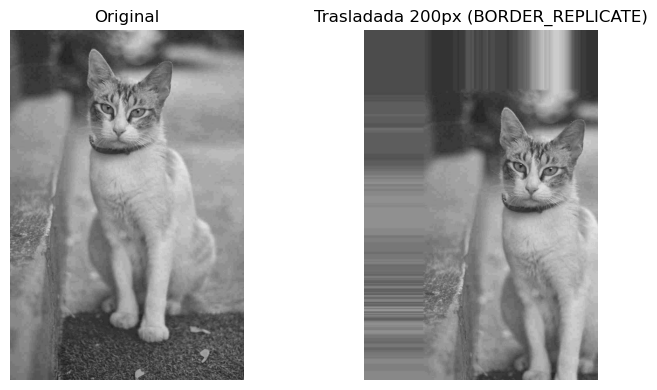

In [5]:
# 1. Cargar la imagen
img = cv2.imread('gato.png')
# Convertir de BGR (OpenCV) a RGB (Matplotlib) si la imagen es a color
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# Obtener alto y ancho de la imagen
alto, ancho = img.shape[:2]

# 2. Definir la matriz de traslación M
# tx = 200 (desplazamiento a la derecha)
# ty = 200 (desplazamiento hacia abajo)
tx = 200
ty = 200
M = np.float32([[1, 0, tx], [0, 1, ty]])

# 3. Aplicar la traslación con borderMode=cv2.BORDER_REPLICATE
img_trasladada = cv2.warpAffine(
    img_rgb, M, (ancho, alto), borderMode=cv2.BORDER_REPLICATE
)

# 4. Mostrar el resultado
plt.figure(figsize=(8, 4))

plt.subplot(1, 2, 1)
plt.imshow(img_rgb)
plt.title('Original')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(img_trasladada)
plt.title('Trasladada 200px (BORDER_REPLICATE)')
plt.axis('off')

plt.tight_layout()
plt.show()

EJERCICIO 2

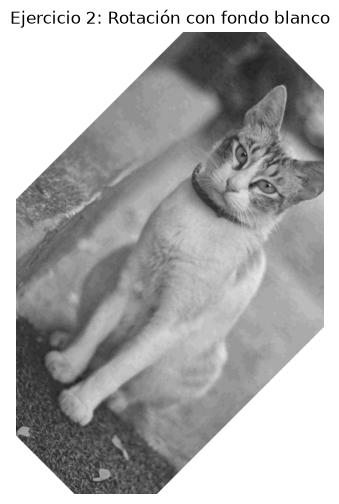

In [6]:
# 1. Cargar la imagen
img = cv2.imread('gato.png')
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

alto, ancho = img.shape[:2]

# 2. Definir el centro de rotación y el ángulo (-45 grados gira en sentido horario)
centro = (ancho / 2, alto / 2)
angulo = -45
escala = 1.0

# Obtener la matriz de rotación 2D
M = cv2.getRotationMatrix2D(centro, angulo, escala)

# 3. Aplicar warpAffine con fondo blanco
# Si la imagen es a color (3 canales), pasamos borderValue=(255, 255, 255)
# Si es escala de grises (1 canal), pasamos borderValue=255
img_rotada = cv2.warpAffine(
    img_rgb, 
    M, 
    (ancho, alto), 
    borderMode=cv2.BORDER_CONSTANT, 
    borderValue=(255, 255, 255) # color del fondo
)

# 4. Mostrar el resultado
plt.figure(figsize=(6, 6))
plt.imshow(img_rotada)
plt.title('Ejercicio 2: Rotación con fondo blanco')
plt.axis('off')
plt.show()

EJERCICIO 3

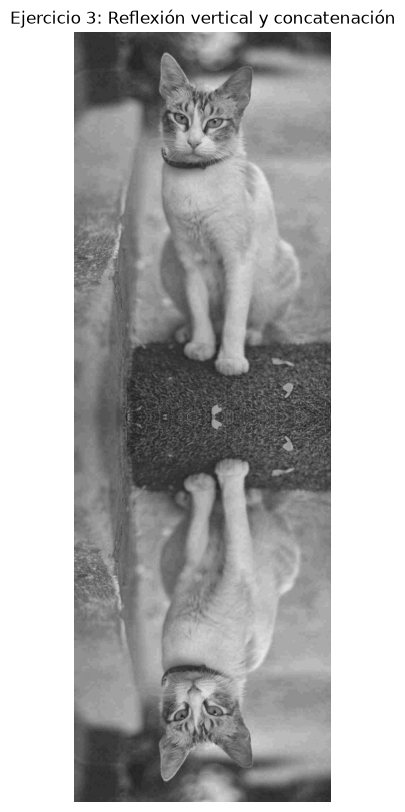

In [10]:
# 1. Cargar la imagen original
img = cv2.imread('gato.png')
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# 2. Realizar la reflexión vertical (flipCode = 0)
img_flip = cv2.flip(img_rgb, 0)

# 3. Concatenar la imagen original y la reflejada verticalmente
img_resultado = cv2.vconcat([img_rgb, img_flip]) # cv2.hconcat (concatenación Horizontal).

# 4. Mostrar el resultado
plt.figure(figsize=(6, 10))
plt.imshow(img_resultado)
plt.title('Ejercicio 3: Reflexión vertical y concatenación')
plt.axis('off')
plt.show()

EJERCICIO 4

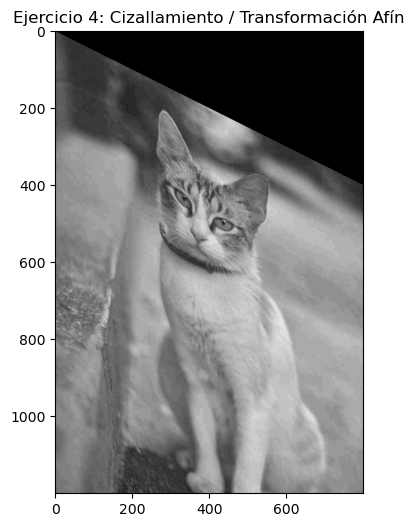

In [8]:

# 1. Cargar la imagen original
img = cv2.imread('gato.png')
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

alto, ancho = img.shape[:2]

# 2. Definir 3 puntos de origen (esquinas de la imagen original)
pts1 = np.float32([
    [0, 0],          # Esquina superior izquierda
    [ancho, 0],      # Esquina superior derecha
    [0, alto]        # Esquina inferior izquierda
])

# 3. Definir los puntos de destino correspondientes
# Desplazamos la esquina superior derecha hacia abajo (p. ej., unos 400px en el eje Y)
pts2 = np.float32([
    [0, 0],          # Se mantiene fija la esquina superior izquierda
    [ancho, 400],    # Se desplaza hacia abajo en Y
    [0, alto]        # Se mantiene fija la esquina inferior izquierda
])

# 4. Obtener la matriz de transformación afín
M = cv2.getAffineTransform(pts1, pts2)

# 5. Aplicar la transformación (los bordes no cubiertos quedan en negro por defecto)
img_shear = cv2.warpAffine(img_rgb, M, (ancho, alto))

# 6. Mostrar el resultado
plt.figure(figsize=(6, 6))
plt.imshow(img_shear)
plt.title('Ejercicio 4: Cizallamiento / Transformación Afín')
plt.show()

### Diferencia: 3 Puntos vs. 4 Puntos

* **3 Puntos (Transformación Afín):**
  * Funciones: `cv2.getAffineTransform()` y `cv2.warpAffine()`.
  * Propiedad: Mantiene el paralelismo entre líneas (paralelogramos).
  * Usos: Rotación, escalado, traslación y cizallamiento (*shear*).

* **4 Puntos (Transformación de Perspectiva):**
  * Funciones: `cv2.getPerspectiveTransform()` y `cv2.warpPerspective()`.
  * Propiedad: NO requiere mantener líneas paralelas (permite puntos de fuga 3D).
  * Usos: Enderezar documentos, corrección de cámara y proyecciones.

In [ ]:
# 2. Definir los 4 puntos de ORIGEN (las 4 esquinas de la imagen original)
pts1 = np.float32([
    [0, 0],         # Esquina superior izquierda
    [ancho, 0],     # Esquina superior derecha
    [0, alto],      # Esquina inferior izquierda
    [ancho, alto]   # Esquina inferior derecha  <-- ¡Aquí sí se incluye!
])

# 3. Definir los 4 puntos de DESTINO (a dónde quieres mover cada esquina)
# Ejemplo: Deformación en perspectiva arrastrando la esquina superior derecha
pts2 = np.float32([
    [0, 0],             # Superior izquierda: se queda fija
    [ancho - 100, 100], # Superior derecha: se mete hacia adentro y baja
    [0, alto],          # Inferior izquierda: se queda fija
    [ancho, alto]       # Inferior derecha: se queda fija
])

 EJERCICIO 5
La estructura de slicing en NumPy para imágenes siempre es:$$\text{imagen}[\mathbf{ymin : ymax}, \, \mathbf{xmin : xmax}]$$
- ymin:ymax: Filas (desde qué píxel vertical empieza la cara hasta dónde termina, contando de arriba a abajo).
- xmin:xmax: Columnas (desde qué píxel horizontal empieza la cara hasta dónde termina, contando de izquierda a derecha).

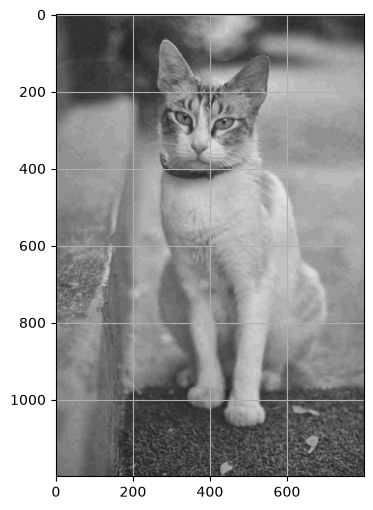

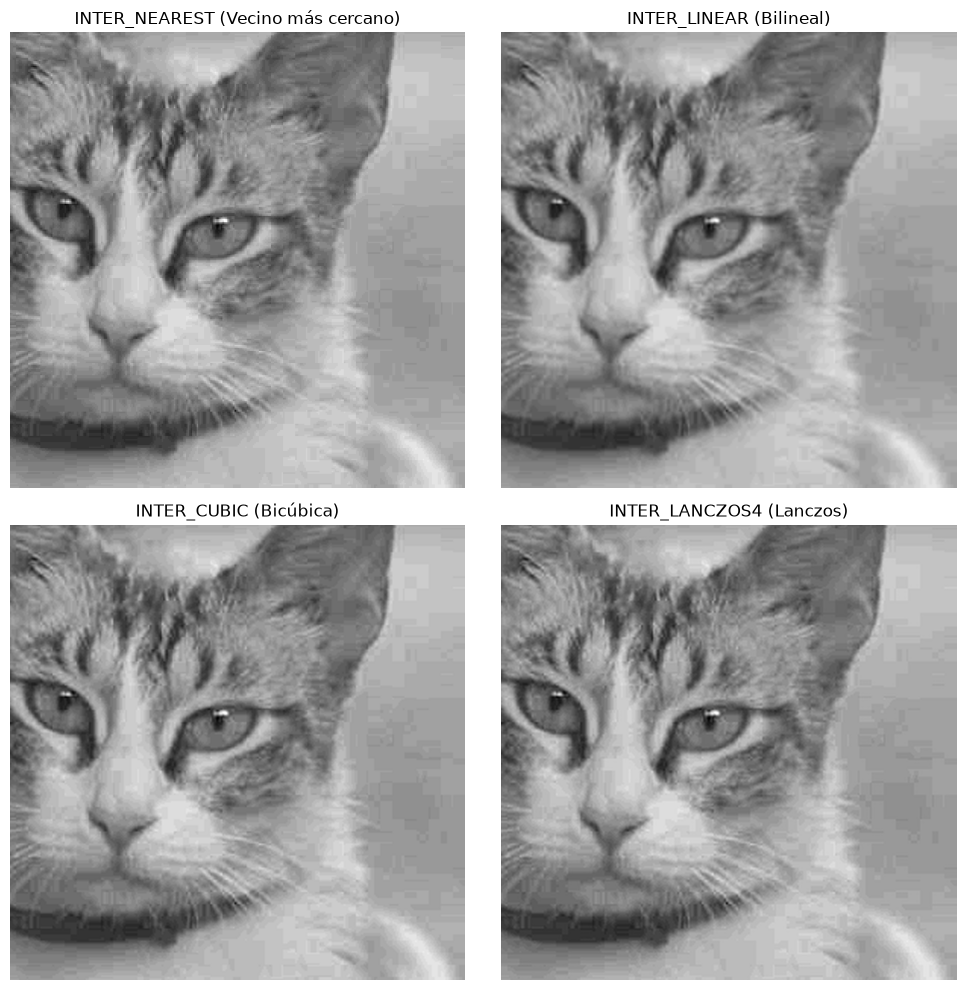

In [12]:
# 1. Cargar la imagen original
img = cv2.imread('gato.png')
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# Muestra la imagen con los ejes en píxeles
plt.figure(figsize=(6, 6))
plt.imshow(img_rgb)
plt.grid(True)  # Activa la cuadrícula para medir fácil
plt.show()

# 2. Recortar la cara del gato utilizando slicing [ymin:ymax, xmin:xmax]
# (Ajusta estas coordenadas según las dimensiones exactas de tu imagen)
cara_gato = img_rgb[150:450, 300:600]

# 3. Redimensionar al doble utilizando distintas interpolaciones
# Opción A: Especificando fx=2, fy=2 y dsize=(0,0)
# Opción B: Pasando el tamaño exacto (ancho * 2, alto * 2)

# Interpolación por vecino más cercano
cara_nearest = cv2.resize(cara_gato, (0, 0), fx=2, fy=2, interpolation=cv2.INTER_NEAREST)

# Interpolación bilineal
cara_linear = cv2.resize(cara_gato, (0, 0), fx=2, fy=2, interpolation=cv2.INTER_LINEAR)

# Interpolación bicúbica
cara_cubic = cv2.resize(cara_gato, (0, 0), fx=2, fy=2, interpolation=cv2.INTER_CUBIC)

# Interpolación Lanczos
cara_lanczos = cv2.resize(cara_gato, (0, 0), fx=2, fy=2, interpolation=cv2.INTER_LANCZOS4)

# 4. Mostrar y comparar los resultados
fig, axes = plt.subplots(2, 2, figsize=(10, 10))

axes[0, 0].imshow(cara_nearest)
axes[0, 0].set_title('INTER_NEAREST (Vecino más cercano)')
axes[0, 0].axis('off')

axes[0, 1].imshow(cara_linear)
axes[0, 1].set_title('INTER_LINEAR (Bilineal)')
axes[0, 1].axis('off')

axes[1, 0].imshow(cara_cubic)
axes[1, 0].set_title('INTER_CUBIC (Bicúbica)')
axes[1, 0].axis('off')

axes[1, 1].imshow(cara_lanczos)
axes[1, 1].set_title('INTER_LANCZOS4 (Lanczos)')
axes[1, 1].axis('off')

plt.tight_layout()
plt.show()

### Métodos de Interpolación al Ampliar una Imagen

Cuando ampliamos una imagen, el programa debe **"inventar" píxeles nuevos** en los espacios vacíos. La diferencia entre cada método radica en cuántos píxeles vecinos consulta y qué fórmula matemática utiliza para calcular ese nuevo color:

* **`INTER_NEAREST` (Vecino más cercano):**
  * **¿Cómo funciona?** No realiza cálculos ni promedios. Simplemente copia el color del píxel original más próximo.
  * **Resultado visual:** Es el método más rápido, pero genera un efecto **"pixelado" o en escalera** (*aliasing*), muy evidente en líneas finas como los bigotes.

* **`INTER_LINEAR` (Bilineal):**
  * **¿Cómo funciona?** Consulta los **$2 \times 2$ píxeles vecinos** (4 en total) y calcula una media ponderada en línea recta entre sus colores.
  * **Resultado visual:** Elimina el pixelado y suaviza los bordes. Es el método estándar por defecto en OpenCV debido a su equilibrio entre velocidad y calidad.

* **`INTER_CUBIC` (Bicúbica):**
  * **¿Cómo funciona?** Analiza un bloque de **$4 \times 4$ píxeles vecinos** (16 en total) y conecta sus tonos usando curvas matemáticas suaves (*splines cúbicos*).
  * **Resultado visual:** Genera bordes más nítidos y detallados que la interpolación bilineal, definiendo mejor las texturas complejas como el pelaje o el iris del ojo. Es la opción recomendada para ampliaciones.

* **`INTER_LANCZOS4` (Lanczos):**
  * **¿Cómo funciona?** Amplía el análisis a una ventana de **$8 \times 8$ píxeles vecinos** (64 en total) mediante la función matemática *sinc*, la cual reconstruye las ondas de la imagen con alta precisión.
  * **Resultado visual:** Ofrece **la mayor nitidez y definición en detalles muy finos**, aunque requiere mayor capacidad de cómputo.

---

### Conclusión práctica

Al ampliar el recorte de la cara del gato al doble de su tamaño original:

1. **`INTER_NEAREST`** deja al descubierto la estructura de cuadrícula de los píxeles (bloques visibles de color).
2. **`INTER_LINEAR`** elimina el pixelado, pero puede suavizar en exceso los bordes.
3. **`INTER_CUBIC`** e **`INTER_LANCZOS4`** producen los resultados más limpios y con mayor sensación de nitidez en las texturas y detalles anatómicos del felino.

EJERCICIO 6

Los 4 puntos de origen dados en el enunciado son:

[320, 140]: Esquina superior izquierda

[620, 85]: Esquina superior derecha

[395, 520]: Esquina inferior izquierda

[720, 440]: Esquina inferior derecha

Debemos definir el tamaño deseado para la nueva imagen del documento (por ejemplo, ancho = 400 y alto = 500) y asociar cada esquina a sus correspondientes coordenadas rectangulares.

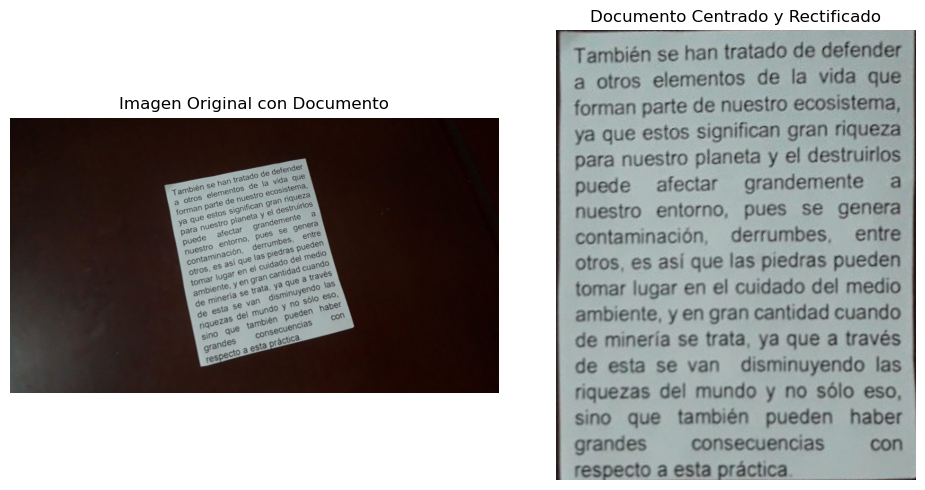

In [13]:
# 1. Cargar la imagen del documento
img = cv2.imread('documento.jpg')
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# 2. Puntos de origen proporcionados en el enunciado
pts1 = np.float32([[320, 140], [620, 85], [395, 520], [720, 440]])

# 3. Definir las dimensiones de la imagen rectificada (ancho y alto)
ancho_doc = 400 # LA IMAGEN RESULTANTE TENDRA 400 PX DE ANCHO Y 500PX DE ALTO
alto_doc = 500

# Puntos de destino correspondientes en la imagen de salida
pts2 = np.float32([
    [0, 0],                     # Superior izquierda
    [ancho_doc, 0],             # Superior derecha
    [0, alto_doc],              # Inferior izquierda
    [ancho_doc, alto_doc]       # Inferior derecha
])

# 4. Obtener la matriz de transformación proyectiva (3x3)
M = cv2.getPerspectiveTransform(pts1, pts2)

# 5. Aplicar la transformación de perspectiva
doc_rectificado = cv2.warpPerspective(img_rgb, M, (ancho_doc, alto_doc))

# 6. Mostrar el resultado
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(img_rgb)
plt.title('Imagen Original con Documento')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(doc_rectificado)
plt.title('Documento Centrado y Rectificado')
plt.axis('off')

plt.tight_layout()
plt.show()